# Ciencia de Datos — EDA 01
# Del análisis univariante al análisis bivariante

**Modalidad:** clase teórico-práctica  
**Dataset:** Salud y hábitos de sueño

## Objetivo de aprendizaje

Aplicar el Análisis bivariante para pasar de describir variables individualmente a explorar relaciones entre dos variables, seleccionando técnicas apropiadas e interpretando los resultados con cautela.

**Metodología:** Pregunta → variables → análisis → evidencia → interpretación → conclusión.

# 1. El caso: comprender los hábitos de sueño

Un equipo de análisis ha recibido datos sobre hábitos de sueño, actividad física, estrés y características personales. Desea comprender qué patrones aparecen en los registros y qué preguntas merecen investigación posterior.

Entre las variables hay edad, ocupación, duración y calidad del sueño, estrés, actividad física, categoría de IMC, frecuencia cardíaca, pasos diarios y trastornos del sueño.

**Pregunta orientadora:** ¿Qué podemos descubrir sin asumir de antemano que una variable causa otra?

**Alcance:** este dataset se usa con fines educativos. Una relación observada no demuestra causalidad ni permite generalizar automáticamente a toda la población. Debemos conocer cómo se obtuvieron los datos y a quiénes representan.

# 2. Preparar el entorno

In [16]:
# %pip install pandas matplotlib seaborn 

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pygwalker as pyg

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 3. Cargar el dataset y comprobar su estructura

Ajusta la ruta a la ubicación de tu archivo CSV. Aquí suponemos que está en una carpeta `datasets` junto al notebook.

In [18]:
df = pd.read_csv("../BDD/sleep.csv")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [19]:
df.shape

(374, 13)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 49.2 KB


### Antes de seguir

Responde en una celda Markdown:

1. ¿Cuántas filas y columnas contiene?
2. ¿Qué variables son numéricas?
3. ¿Qué variables son categóricas?
4. ¿Hay alguna variable que necesite preparación antes de analizarla?

# 4. Del análisis univariante al EDA

## 4.1 Recordatorio: análisis univariante

Estudia una variable individualmente: su tendencia central, dispersión, valores frecuentes y distribución.

## 4.2 ¿Qué añade el análisis bivariante?

Estudia dos variables para explorar una posible relación, diferencia o asociación. Por ejemplo:

- duración del sueño y calidad del sueño;
- duración del sueño según grupo;
- distribución de trastornos del sueño entre categorías.

**Primero se formula la pregunta; después se elige el análisis o el gráfico.**

# 5. Bivariante: variable numérica + variable numérica

## Pregunta 1

**¿Qué patrón se observa entre la duración del sueño y la calidad del sueño?**

Escribe primero una expectativa inicial. Luego compárala con la evidencia.

In [21]:
df[["Sleep Duration", "Quality of Sleep"]].describe()

,Sleep Duration,Quality of Sleep
count,374.000000,374.000000
mean,7.132086,7.312834
std,0.795657,1.196956
min,5.800000,4.000000
25%,6.400000,6.000000
50%,7.200000,7.000000
75%,7.800000,8.000000
max,8.500000,9.000000


## 5.1 Visualizar los registros
Un diagrama de dispersión representa cada observación como un punto.

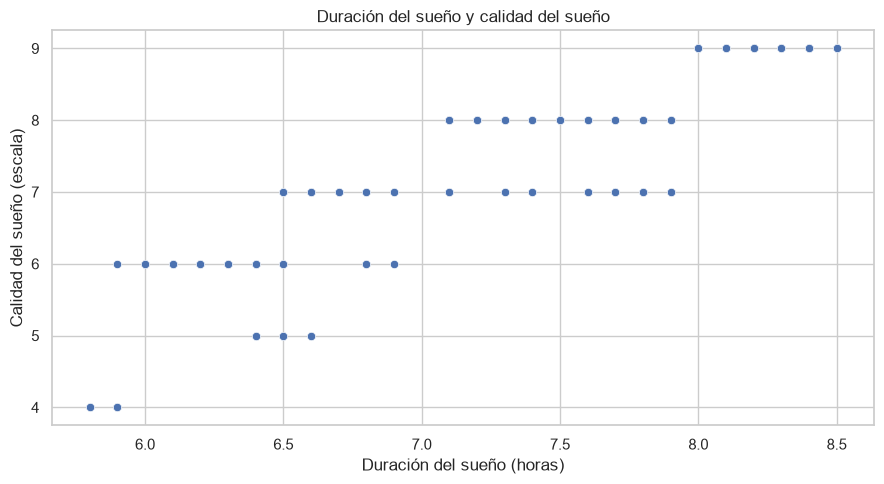

In [22]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Sleep Duration", y="Quality of Sleep")
plt.title("Duración del sueño y calidad del sueño")
plt.xlabel("Duración del sueño (horas)")
plt.ylabel("Calidad del sueño (escala)")
plt.tight_layout()
plt.show()

## 5.2 Leer el gráfico

Observa:

- **Dirección:** si ambas variables tienden a aumentar o si una disminuye cuando la otra aumenta.
- **Forma:** patrón lineal, curvo o poco evidente.
- **Concentración:** dónde se agrupan los puntos.
- **Dispersión:** cuánto varían los puntos.
- **Puntos aislados:** observaciones que podrían merecer revisión.

### Actividad de interpretación

1. ¿Qué patrón observas?
2. ¿Qué evidencia respalda tu interpretación?
3. ¿Hay excepciones o dispersión?
4. ¿Qué no puedes concluir únicamente con este gráfico?

#### Escribe la interpretación en una aquí.

## 5.3 Correlación: resumen numérico exploratorio

La correlación resume la dirección e intensidad de una relación **lineal** entre dos variables numéricas y suele estar entre -1 y 1:

- cercano a `1`: asociación lineal positiva;
- cercano a `-1`: asociación lineal negativa;
- cercano a `0`: poca o ninguna asociación lineal.

Un valor cercano a cero no descarta una relación no lineal. La correlación no demuestra causalidad.

In [23]:
correlacion = df["Sleep Duration"].corr(df["Quality of Sleep"])
print(f"Correlación: {correlacion:.3f}")

Correlación: 0.883


### Actividad

Compara el valor de correlación con el diagrama de dispersión.

- ¿Ambos ofrecen una lectura compatible?
- ¿El valor numérico resume completamente el patrón?
- ¿Qué información aporta el gráfico que no aporta el coeficiente?

No interpretes la correlación sin mirar los puntos.

# 6. Bivariante: variable categórica + variable numérica

## Pregunta 2

**¿Qué diferencias se observan en la duración del sueño entre los grupos de `Gender`?**

Primero calcularemos resúmenes por grupo. No basta con comparar promedios: considera también la dispersión y el tamaño de los grupos.

In [24]:
df.groupby("Gender")["Sleep Duration"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Gender,,,,,,
Female,185,7.229730,7.2,0.879434,5.8,8.5
Male,189,7.036508,7.2,0.693197,5.9,8.1


## 6.1 Comparar distribuciones con un boxplot
El boxplot ayuda a comparar medianas, cuartiles, dispersión y posibles valores atípicos.

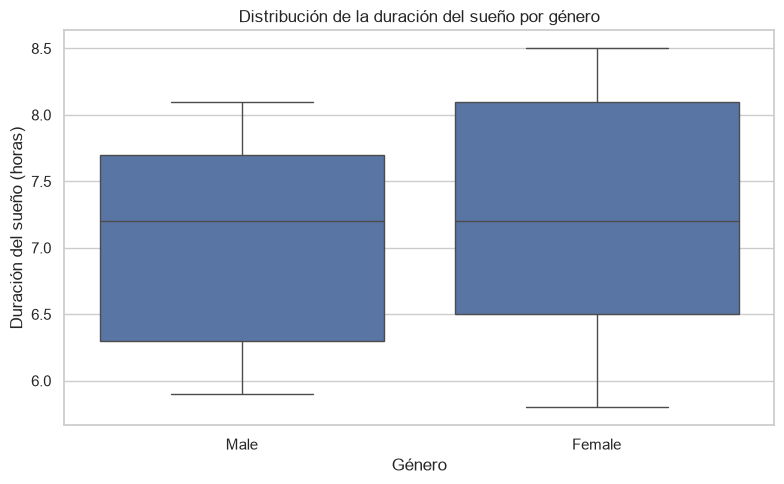

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Gender", y="Sleep Duration")
plt.title("Distribución de la duración del sueño por género")
plt.xlabel("Género")
plt.ylabel("Duración del sueño (horas)")
plt.tight_layout()
plt.show()

### Actividad de interpretación

1. Compara los resúmenes numéricos.
2. Describe una observación respaldada por el boxplot.
3. Señala una limitación de la comparación.

No afirmar que el género causa una duración específica del sueño. Describe lo que muestran estos registros.

In [26]:
# Escribe la interpretación en una celda Markdown.

# 7. Bivariante: variable categórica + variable categórica

## Pregunta 3

**¿Cómo se distribuyen las categorías de `Sleep Disorder` dentro de cada grupo de `Gender`?**

Una tabla de contingencia permite contar las combinaciones observadas entre categorías.

In [27]:
tabla_frecuencias = pd.crosstab(df["Gender"], df["Sleep Disorder"])
tabla_frecuencias

Sleep Disorder,Insomnia,Sleep Apnea
Gender,,
Female,36,67
Male,41,11


## 7.1 Comparar proporciones dentro de cada grupo
Las frecuencias absolutas pueden confundir si los grupos tienen tamaños distintos. Calcularemos porcentajes por fila.

In [28]:
tabla_porcentajes = pd.crosstab(
    df["Gender"],
    df["Sleep Disorder"],
    normalize="index"
) * 100

tabla_porcentajes.round(1)

Sleep Disorder,Insomnia,Sleep Apnea
Gender,,
Female,35.0,65.0
Male,78.8,21.2


### Actividad de interpretación

1. ¿Qué categoría de trastorno aparece con mayor frecuencia en cada grupo?
2. ¿Qué diferencia hay entre comparar cantidades y porcentajes?
3. ¿Qué conclusión descriptiva puedes redactar?
4. ¿Por qué la tabla no demuestra causalidad?

Si `Sleep Disorder` contiene una categoría como `None`, interprétala según el diccionario de datos; no la confundas automáticamente con un valor nulo de Pandas.

In [29]:
# Escribe tu interpretación en una celda Markdown.

# 8. Elegir el análisis según los tipos de variables

| Tipos de variables | Pregunta típica | Herramientas exploratorias |
|---|---|---|
| Numérica + numérica | ¿Qué patrón o asociación se observa? | Diagrama de dispersión, correlación |
| Categórica + numérica | ¿Cómo cambia la distribución entre grupos? | Resumen por grupo, boxplot |
| Categórica + categórica | ¿Cómo se distribuyen las categorías conjuntamente? | Tabla de contingencia, porcentajes, barras |

Es una guía para elegir una técnica apropiada a la pregunta, no una lista rígida.

# 9. Práctica guiada: investiga tu propia pregunta

Plantea una pregunta distinta de las tres ya analizadas.

## Requisitos

1. Formular una pregunta concreta que pueda responderse con el dataset.
2. Identifica las dos variables necesarias.
3. Explica por qué esas variables ayudan a responderla.
4. Selecciona una técnica de análisis adecuada.
5. Presenta el resultado.
6. Interpreta la evidencia.
7. Señala una limitación de tu conclusión.



In [30]:
# 1. Escribe tu pregunta en una celda Markdown.
# 2. Selecciona las variables y realiza el análisis aquí.

In [31]:
# Si tu pregunta se beneficia de una visualización, constrúyela aquí.

In [32]:
# Escribe tu interpretación y limitación en una celda Markdown.

# 10. Cierre: de una asociación a un hallazgo

Completa estas frases a partir de tu análisis:

- **Pregunta:** ¿qué quería investigar?
- **Evidencia:** ¿qué resultado, tabla o gráfico respalda la respuesta?
- **Interpretación:** ¿qué patrón parece mostrar la evidencia?
- **Limitación:** ¿qué no puedo afirmar?
- **Siguiente paso:** ¿qué información o análisis sería útil?

## Ideas que debes recordar

- Una asociación no demuestra causalidad.
- Un gráfico debe responder una pregunta concreta.
- Un estadístico resume información, pero puede ocultar detalles.
- Las diferencias entre grupos deben interpretarse considerando sus tamaños y distribuciones.
- Las conclusiones deben ser proporcionales a la evidencia disponible.

**El EDA consiste en formular preguntas, investigar los datos y comunicar lo que la evidencia permite sostener.**

# 11. Lista de verificación

- [ ] El archivo se carga correctamente.
- [ ] He revisado su estructura y las variables utilizadas.
- [ ] Cada análisis responde una pregunta concreta.
- [ ] He elegido técnicas acordes con los tipos de variables.
- [ ] He interpretado los resultados con mis propias palabras.
- [ ] No he confundido asociación con causalidad.
- [ ] He indicado al menos una limitación.
- [ ] Las celdas se ejecutan en orden y los resultados son visibles.